In [ ]:
import sys
sys.path.insert(0,'../CRLDenv/lib/python3.11/site-packages')
print(sys.path)

['../CRLDenv/lib/python3.11/site-packages', '/home/clemence/Documents/PhD/Code/DistRLdynamics', '/usr/lib/python39.zip', '/usr/lib/python3.9', '/usr/lib/python3.9/lib-dynload', '', '/home/clemence/Documents/PhD/Code/pyCRLD/CRLDenv/lib/python3.9/site-packages']


In [ ]:
import numpy as np
from scipy.stats import norm

import jax.numpy as jnp
from jax import jit
from functools import partial

from pyCRLD.Agents.Base import abase
from pyCRLD.Utils.Helpers import *

import pandas as pd
# import seaborn as sns

In [ ]:
from pyCRLD.Environments.SocialDilemma import SocialDilemma
from pyCRLD.Environments.EcologicalPublicGood import EcologicalPublicGood
from pyCRLD.Agents.StrategySARSA import stratSARSA
from qBaseDistR import qbaseDist
from qBaseSARSA import qbaseSARSA
from pyCRLD.Utils.Trajectories1D import trajectories_1D 
from pyCRLD.Utils.PhasePlot import phaseplot
import matplotlib.pyplot as plt

In [ ]:
from pyCRLD.Utils import FlowPlot as fp

In [ ]:
env = SocialDilemma(R=1, S=-2, T=3, P=0)

In [ ]:
def compute_error(Xs, sigma, lr, gammas, path, version):
    errors = np.zeros((len(gammas), len(Xs)))
    for j, gamma in enumerate(gammas):
        print("Gamma "+str(gamma))
        mae = stratSARSA(env=env, learning_rates=0.1, 
                         discount_factors=gamma, choice_intensities=4., use_prefactor=True)
        db = qbaseSARSA(env, nr_reward_bins=29, discretization_sigma=0.1, 
                        learning_rates=0.1, discount_factors=gamma, 
                        choice_intensities=4, Rmin=-2, Rmax=3,
                        method='mean', use_prefactor=True)
        for k, x in enumerate(Xs):
            distRPE = db.TDerror(x, norm=True)
            detRPE = mae.TDerror(x, norm=True)
            error = np.linalg.norm(detRPE-distRPE)  # error in degraded env
            errors[j, k] = error
    index = ["gamma="+str(gamma) for gamma in gammas]
    columns = ["x="+str(x) for x in np.linspace(0, 1, len(Xs))]
    df = pd.DataFrame(errors, index=index, columns=columns)
    df.to_csv(path+"PD_error_df_"+version+".csv")
    return df

In [ ]:
# Initialization
path = "data/error_calculation/"
version = "2025-02-25-v0.0"
lr = 0.1
gammas = np.linspace(0, 1, 41)
sigma = 0.1
Xs = []
Pc = np.linspace(0, 1, 101)
Pc[0] = 0.001
Pc[-1] = 0.999
for i, p in enumerate(Pc):
    Xisa = np.zeros((2, 1, 2))
    Xisa[:, :, 0] = p
    Xisa[:, :, 1] = 1-p
    Xs.append(Xisa)

In [ ]:
Xs[33]

array([[[0.33, 0.67]],

       [[0.33, 0.67]]])

In [ ]:
errors = compute_error(Xs, sigma, lr, gammas, path, version)

Gamma 0.0
Gamma 0.025
Gamma 0.05
Gamma 0.07500000000000001
Gamma 0.1
Gamma 0.125
Gamma 0.15000000000000002
Gamma 0.17500000000000002
Gamma 0.2
Gamma 0.225
Gamma 0.25
Gamma 0.275
Gamma 0.30000000000000004
Gamma 0.325
Gamma 0.35000000000000003
Gamma 0.375
Gamma 0.4
Gamma 0.42500000000000004
Gamma 0.45
Gamma 0.47500000000000003
Gamma 0.5
Gamma 0.525
Gamma 0.55
Gamma 0.5750000000000001
Gamma 0.6000000000000001
Gamma 0.625
Gamma 0.65
Gamma 0.675
Gamma 0.7000000000000001
Gamma 0.7250000000000001
Gamma 0.75
Gamma 0.775
Gamma 0.8
Gamma 0.8250000000000001
Gamma 0.8500000000000001
Gamma 0.875
Gamma 0.9
Gamma 0.925
Gamma 0.9500000000000001
Gamma 0.9750000000000001
Gamma 1.0


In [ ]:
# Retrieve data and put it in array
errors = np.zeros((len(gammas), len(Xs)))
df = pd.read_csv(path+"PD_error_df_"+version+".csv")
npdf = df.to_numpy()
errors = npdf[:, 1:]

In [ ]:
mean_error = np.mean(errors, axis=1)

Text(0, 0.5, 'mean error')

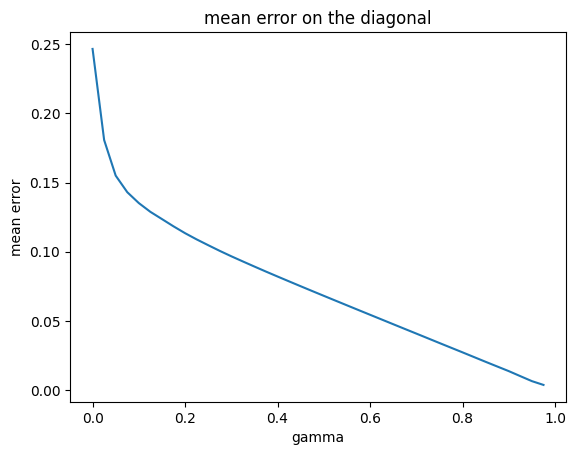

In [ ]:
plt.figure()
plt.plot(gammas, mean_error)
plt.xlabel("gamma")
plt.title("mean error on the diagonal")
plt.ylabel("mean error")

In [ ]:
def compute_error(betas, Xs, sigma, lr, gammas, path, version):
    for i, beta in enumerate(betas):
        errors = np.zeros((len(gammas), len(Xs)))
        for j, gamma in enumerate(gammas):
            print("Beta "+str(beta)+" Gamma "+str(gamma))
            mae = stratSARSA(env=env, learning_rates=0.1, 
                             discount_factors=gamma, choice_intensities=beta, use_prefactor=True)
            db = qbaseSARSA(env, nr_reward_bins=29, discretization_sigma=0.1, 
                            learning_rates=0.1, discount_factors=gamma, 
                            choice_intensities=beta, Rmin=-2, Rmax=3,
                            method='mean', use_prefactor=True)
            for k, x in enumerate(Xs):
                distRPE = db.TDerror(x, norm=True)
                detRPE = mae.TDerror(x, norm=True)
                error = np.linalg.norm(detRPE-distRPE)  # error in degraded env
                errors[j, k] = error
        index = ["gamma="+str(gamma) for gamma in gammas]
        columns = ["x="+str(x) for x in np.linspace(0, 1, len(Xs))]
        df = pd.DataFrame(errors, index=index, columns=columns)
        df.to_csv(path+"PD_error_df_beta_"+str(beta)+"_"+version+".csv")
    return df

In [ ]:
# Initialization
path = "data/error_calculation/"
version = "betas_2025-02-25-v0.0"
lr = 0.1
gammas = np.linspace(0, 1, 41)
betas = np.array([0.5, 1., 2., 4., 8., 16., 32., 64., 128.])
sigma = 0.1
Xs = []
Pc = np.linspace(0, 1, 101)
Pc[0] = 0.001
Pc[-1] = 0.999
for i, p in enumerate(Pc):
    Xisa = np.zeros((2, 1, 2))
    Xisa[:, :, 0] = p
    Xisa[:, :, 1] = 1-p
    Xs.append(Xisa)

In [ ]:
errors = compute_error(betas, Xs, sigma, lr, gammas, path, version)

Beta 0.5 Gamma 0.0
Beta 0.5 Gamma 0.025
Beta 0.5 Gamma 0.05
Beta 0.5 Gamma 0.07500000000000001
Beta 0.5 Gamma 0.1
Beta 0.5 Gamma 0.125
Beta 0.5 Gamma 0.15000000000000002
Beta 0.5 Gamma 0.17500000000000002
Beta 0.5 Gamma 0.2
Beta 0.5 Gamma 0.225
Beta 0.5 Gamma 0.25
Beta 0.5 Gamma 0.275
Beta 0.5 Gamma 0.30000000000000004
Beta 0.5 Gamma 0.325
Beta 0.5 Gamma 0.35000000000000003
Beta 0.5 Gamma 0.375
Beta 0.5 Gamma 0.4
Beta 0.5 Gamma 0.42500000000000004
Beta 0.5 Gamma 0.45
Beta 0.5 Gamma 0.47500000000000003
Beta 0.5 Gamma 0.5
Beta 0.5 Gamma 0.525
Beta 0.5 Gamma 0.55
Beta 0.5 Gamma 0.5750000000000001
Beta 0.5 Gamma 0.6000000000000001
Beta 0.5 Gamma 0.625
Beta 0.5 Gamma 0.65
Beta 0.5 Gamma 0.675
Beta 0.5 Gamma 0.7000000000000001
Beta 0.5 Gamma 0.7250000000000001
Beta 0.5 Gamma 0.75
Beta 0.5 Gamma 0.775
Beta 0.5 Gamma 0.8
Beta 0.5 Gamma 0.8250000000000001
Beta 0.5 Gamma 0.8500000000000001
Beta 0.5 Gamma 0.875
Beta 0.5 Gamma 0.9
Beta 0.5 Gamma 0.925
Beta 0.5 Gamma 0.9500000000000001
Beta 0.5 Gam

Beta 64.0 Gamma 0.8
Beta 64.0 Gamma 0.8250000000000001
Beta 64.0 Gamma 0.8500000000000001
Beta 64.0 Gamma 0.875
Beta 64.0 Gamma 0.9
Beta 64.0 Gamma 0.925
Beta 64.0 Gamma 0.9500000000000001
Beta 64.0 Gamma 0.9750000000000001
Beta 64.0 Gamma 1.0
Beta 128.0 Gamma 0.0
Beta 128.0 Gamma 0.025
Beta 128.0 Gamma 0.05
Beta 128.0 Gamma 0.07500000000000001
Beta 128.0 Gamma 0.1
Beta 128.0 Gamma 0.125
Beta 128.0 Gamma 0.15000000000000002
Beta 128.0 Gamma 0.17500000000000002
Beta 128.0 Gamma 0.2
Beta 128.0 Gamma 0.225
Beta 128.0 Gamma 0.25
Beta 128.0 Gamma 0.275
Beta 128.0 Gamma 0.30000000000000004
Beta 128.0 Gamma 0.325
Beta 128.0 Gamma 0.35000000000000003
Beta 128.0 Gamma 0.375
Beta 128.0 Gamma 0.4
Beta 128.0 Gamma 0.42500000000000004
Beta 128.0 Gamma 0.45
Beta 128.0 Gamma 0.47500000000000003
Beta 128.0 Gamma 0.5
Beta 128.0 Gamma 0.525
Beta 128.0 Gamma 0.55
Beta 128.0 Gamma 0.5750000000000001
Beta 128.0 Gamma 0.6000000000000001
Beta 128.0 Gamma 0.625
Beta 128.0 Gamma 0.65
Beta 128.0 Gamma 0.675
Bet

In [ ]:
# Retrieve data and put it in array
errors = np.zeros((len(betas), len(gammas), len(Xs)))
for i, beta in enumerate(betas):
    df = pd.read_csv(path+"PD_error_df_beta_"+str(beta)+"_"+version+".csv")
    npdf = df.to_numpy()
    errors[i, :, :] = npdf[:, 1:]

In [ ]:
mean_error = np.mean(errors, axis=2)

Text(0, 0.5, 'mean error')

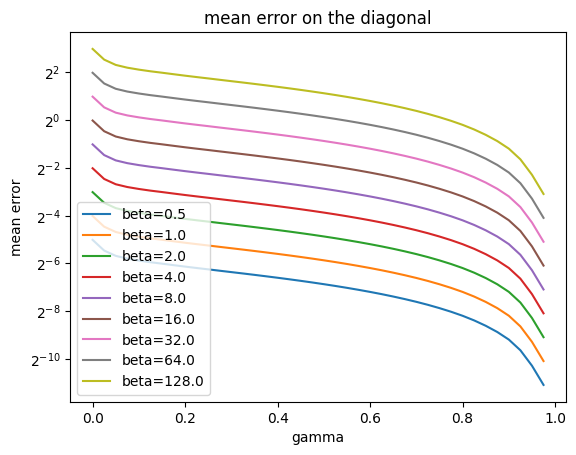

In [ ]:
plt.figure()
for i, beta in enumerate(betas):
    plt.plot(gammas, mean_error[i, :], label="beta="+str(beta))
plt.yscale('log', base=2)
plt.xlabel("gamma")
plt.legend()
plt.title("mean error on the diagonal")
plt.ylabel("mean error")

In [ ]:
def compute_error(bins, Xs, sigmas, lr, gamma, path, version):
    for i, binn in enumerate(bins):
        errors = np.zeros((len(sigmas), len(Xs)))
        for j, sigma in enumerate(sigmas):
            print("Bin "+str(binn)+" Sigma "+str(sigma))
            mae = stratSARSA(env=env, learning_rates=lr, 
                             discount_factors=gamma, choice_intensities=4, use_prefactor=True)
            db = qbaseSARSA(env, nr_reward_bins=binn, discretization_sigma=sigma, 
                            learning_rates=lr, discount_factors=gamma, 
                            choice_intensities=4, Rmin=-2, Rmax=3,
                            method='mean', use_prefactor=True)
            for k, x in enumerate(Xs):
                distRPE = db.TDerror(x, norm=True)
                detRPE = mae.TDerror(x, norm=True)
                error = np.linalg.norm(detRPE-distRPE)  # error in degraded env
                errors[j, k] = error
        index = ["sigma="+str(sigma) for sigma in sigmas]
        columns = ["x="+str(x) for x in np.linspace(0, 1, len(Xs))]
        df = pd.DataFrame(errors, index=index, columns=columns)
        df.to_csv(path+"PD_error_df_bin_"+str(binn)+"_"+version+".csv")
    return df

In [ ]:
# Initialization
path = "data/error_calculation/"
version = "gamma09_2025-02-25-v0.0"
lr = 0.1
gamma = 0.9
bins = np.array([29])
sigmas = np.linspace(0.05, 2.5, 50)
Xs = []
Pc = np.linspace(0, 1, 101)
Pc[0] = 0.001
Pc[-1] = 0.999
for i, p in enumerate(Pc):
    Xisa = np.zeros((2, 1, 2))
    Xisa[:, :, 0] = p
    Xisa[:, :, 1] = 1-p
    Xs.append(Xisa)

In [ ]:
errors = compute_error(bins, Xs, sigmas, lr, gamma, path, version)

Bin 29 Sigma 0.05
Bin 29 Sigma 0.1
Bin 29 Sigma 0.15000000000000002
Bin 29 Sigma 0.2
Bin 29 Sigma 0.25
Bin 29 Sigma 0.3
Bin 29 Sigma 0.35000000000000003
Bin 29 Sigma 0.4
Bin 29 Sigma 0.45
Bin 29 Sigma 0.5
Bin 29 Sigma 0.55
Bin 29 Sigma 0.6000000000000001
Bin 29 Sigma 0.6500000000000001
Bin 29 Sigma 0.7000000000000001
Bin 29 Sigma 0.7500000000000001
Bin 29 Sigma 0.8
Bin 29 Sigma 0.8500000000000001
Bin 29 Sigma 0.9000000000000001
Bin 29 Sigma 0.9500000000000001
Bin 29 Sigma 1.0
Bin 29 Sigma 1.05
Bin 29 Sigma 1.1
Bin 29 Sigma 1.1500000000000001
Bin 29 Sigma 1.2000000000000002
Bin 29 Sigma 1.2500000000000002
Bin 29 Sigma 1.3
Bin 29 Sigma 1.35
Bin 29 Sigma 1.4000000000000001
Bin 29 Sigma 1.4500000000000002
Bin 29 Sigma 1.5000000000000002
Bin 29 Sigma 1.55
Bin 29 Sigma 1.6
Bin 29 Sigma 1.6500000000000001
Bin 29 Sigma 1.7000000000000002
Bin 29 Sigma 1.7500000000000002
Bin 29 Sigma 1.8
Bin 29 Sigma 1.85
Bin 29 Sigma 1.9000000000000001
Bin 29 Sigma 1.9500000000000002
Bin 29 Sigma 2.0
Bin 29 Sig

In [ ]:
plt.figure()
for i, binn in enumerate(bins):
    plt.plot(sigmas, mean_error[i, :], label="bin="+str(binn))
plt.xlabel("sigma")
plt.legend()
plt.title("mean error on the diagonal, gamma=0.9")
plt.ylabel("mean error")

In [ ]:
mae = stratSARSA(env=env, learning_rates=0.1, discount_factors=0.99, choice_intensities=4., use_prefactor=True)
db = qbaseSARSA(env, nr_reward_bins=29, discretization_sigma=0.05, 
                learning_rates=0.1, discount_factors=0.99, 
                choice_intensities=4, Rmin=-2, Rmax=3,
                method='mean', use_prefactor=True)

[<Axes: >]

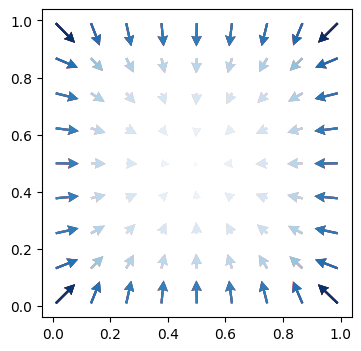

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(4, 4))
x = ([0], [0], [0]) 
y = ([1], [0], [0])
fp.plot_strategy_flow(mae, x, y, flowarrow_points = np.linspace(0.01 ,0.99, 9), NrRandom=16, cmap="Reds", axes=ax)
fp.plot_strategy_flow(db, x, y, flowarrow_points = np.linspace(0.01 ,0.99, 9), NrRandom=16, cmap="Blues", axes=ax)

In [ ]:
mae = stratSARSA(env=env, learning_rates=0.1, discount_factors=0, choice_intensities=4., use_prefactor=True)
db = qbaseSARSA(env, nr_reward_bins=29, discretization_sigma=0.05, 
                learning_rates=0.1, discount_factors=0, 
                choice_intensities=4, Rmin=-2, Rmax=3,
                method='mean', use_prefactor=True)

[<Axes: >]

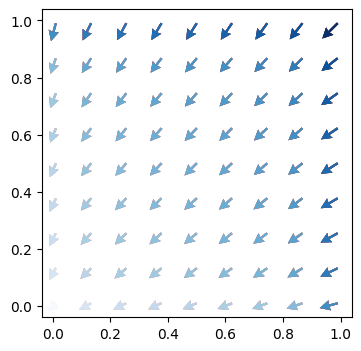

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(4, 4))
x = ([0], [0], [0]) 
y = ([1], [0], [0])
fp.plot_strategy_flow(mae, x, y, flowarrow_points = np.linspace(0.01 ,0.99, 9), NrRandom=16, cmap="Reds", axes=ax)
fp.plot_strategy_flow(db, x, y, flowarrow_points = np.linspace(0.01 ,0.99, 9), NrRandom=16, cmap="Blues", axes=ax)

In [ ]:
mae = stratSARSA(env=env, learning_rates=0.1, discount_factors=0.4, choice_intensities=4., use_prefactor=True)
db = qbaseSARSA(env, nr_reward_bins=29, discretization_sigma=0.05, 
                learning_rates=0.1, discount_factors=0.4, 
                choice_intensities=4, Rmin=-2, Rmax=3,
                method='mean', use_prefactor=True)

[<Axes: >]

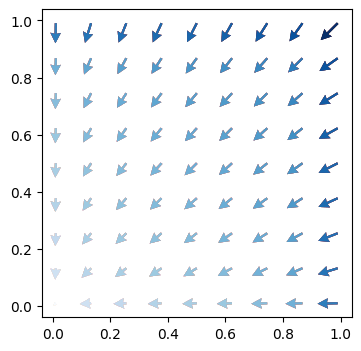

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(4, 4))
x = ([0], [0], [0]) 
y = ([1], [0], [0])
fp.plot_strategy_flow(mae, x, y, flowarrow_points = np.linspace(0.01 ,0.99, 9), NrRandom=16, cmap="Reds", axes=ax)
fp.plot_strategy_flow(db, x, y, flowarrow_points = np.linspace(0.01 ,0.99, 9), NrRandom=16, cmap="Blues", axes=ax)

In [ ]:
mae = stratSARSA(env=env, learning_rates=0.1, discount_factors=0.9, choice_intensities=150, use_prefactor=True)
db = qbaseSARSA(env, nr_reward_bins=29, discretization_sigma=0.05, 
                learning_rates=0.1, discount_factors=0.9, 
                choice_intensities=150, Rmin=-2, Rmax=3,
                method='mean', use_prefactor=True)

[<Axes: >]

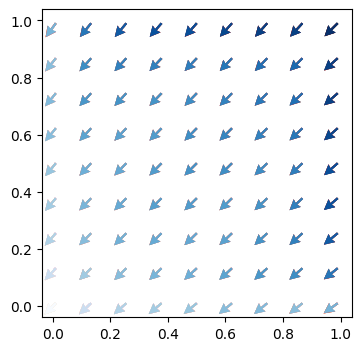

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(4, 4))
x = ([0], [0], [0]) 
y = ([1], [0], [0])
fp.plot_strategy_flow(mae, x, y, flowarrow_points = np.linspace(0.01 ,0.99, 9), NrRandom=16, cmap="Reds", axes=ax)
fp.plot_strategy_flow(db, x, y, flowarrow_points = np.linspace(0.01 ,0.99, 9), NrRandom=16, cmap="Blues", axes=ax)

In [ ]:
mae = stratSARSA(env=env, learning_rates=0.1, discount_factors=0.99, choice_intensities=4., use_prefactor=True)
db = qbaseSARSA(env, nr_reward_bins=29, discretization_sigma=0.05, 
                learning_rates=0.1, discount_factors=0.99, 
                choice_intensities=4., Rmin=-2, Rmax=3,
                method='weights', wU=10, use_prefactor=True)  # optimistic agent

[<Axes: >]

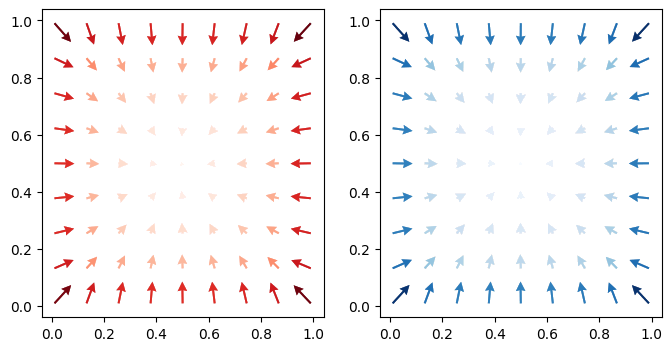

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 4))
x = ([0], [0], [0]) 
y = ([1], [0], [0])
fp.plot_strategy_flow(mae, x, y, flowarrow_points = np.linspace(0.01 ,0.99, 9), NrRandom=16, cmap="Reds", axes=ax1)
fp.plot_strategy_flow(db, x, y, flowarrow_points = np.linspace(0.01 ,0.99, 9), NrRandom=16, cmap="Blues", axes=ax2)

In [ ]:
X = np.ones((2, 1, 2)) * 0.5

In [ ]:
np.linspace(0.01, 0.99, 9)

array([0.01  , 0.1325, 0.255 , 0.3775, 0.5   , 0.6225, 0.745 , 0.8675,
       0.99  ])

In [ ]:
X[0, :, 0] = 0.745
X[0, :, 1] = 0.255
X[1, :, 0] = 0.3775
X[1, :, 1] = 0.6225

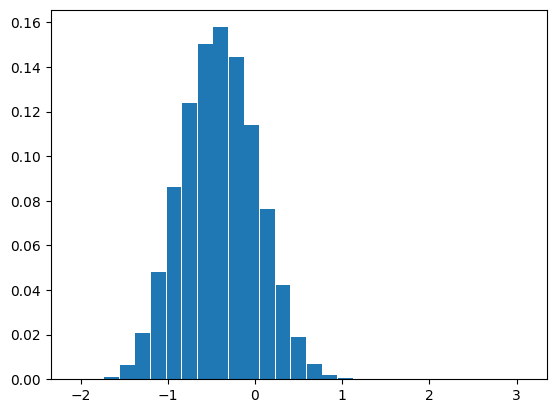

In [ ]:
plt.figure()
plt.bar(db.gridpoints, db.Qisaq(X)[0, 0, 0, :], width=.95*db.gridwidth)
plt.show()

In [ ]:
db.TDerror(X)

Array([[[-9.348486 , -1.1335082]],

       [[27.045614 , 33.688297 ]]], dtype=float32)

In [ ]:
x1 = 0.745
x2 = np.linspace(0.01, 0.99, 9)

In [ ]:
tdes = np.zeros((len(x2)))
q = np.zeros((len(x2)))
qm = np.zeros((len(x2)))
qisaq = np.zeros((len(x2), 29))
for i, x in enumerate(x2):
    X = np.ones((2, 1, 2))
    X[0, :, 0] = x1
    X[0, :, 1] = 1 - x1
    X[1, :, 0] = x
    X[1, :, 1] = 1 - x
    tdes[i] = db.TDerror(X, norm=True)[1, 0, 0]
    q[i] = db._Qisa(X)[1, 0, 0]
    qm[i] = np.dot(db.gridpoints, db.Qisaq(X)[1, 0, 0, :])
    qisaq[i, :] = db.Qisaq(X)[1, 0, 0, :]

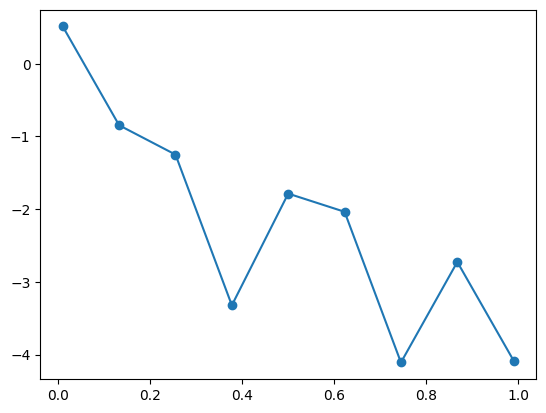

In [ ]:
plt.figure()
plt.plot(x2, tdes, '-o')
plt.show()

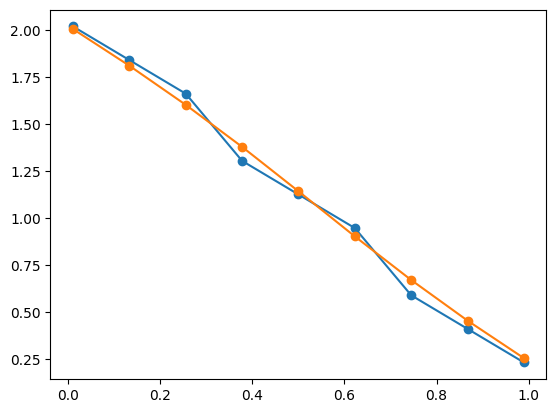

In [ ]:
plt.figure()
plt.plot(x2, q, '-o')
plt.plot(x2, qm, '-o')
plt.show()

In [ ]:
from Methods import expectile

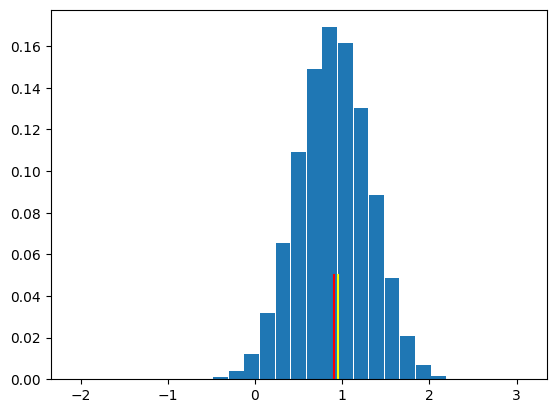

In [ ]:
qbar = qisaq[5, :]
m = np.dot(db.gridpoints, qbar)
e = expectile(.5, qbar, db.gridpoints)

plt.figure()
plt.bar(db.gridpoints, qbar, width=0.95*db.gridwidth)
plt.plot([m, m], [0, 0.05], color='red')
plt.plot([e, e], [0, 0.05], color='yellow')
plt.show()